['Name', 'Ingredients', 'Diet', 'cook_time', 'flavor_profile', 'course', 'state', 'region']
Mode of state: Gujarat
Remaining -1 in state: 0
Region for mode state: West
Mean cooking time: 39.028688524590166
Remaining -1 in cook_time: 0
['Name', 'Ingredients', 'Diet', 'cook_time', 'flavor_profile', 'course', 'state', 'region']


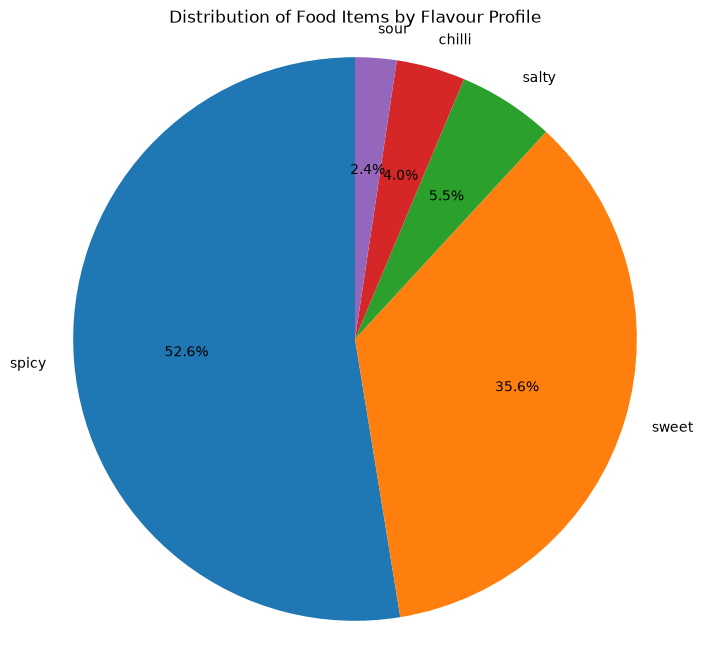

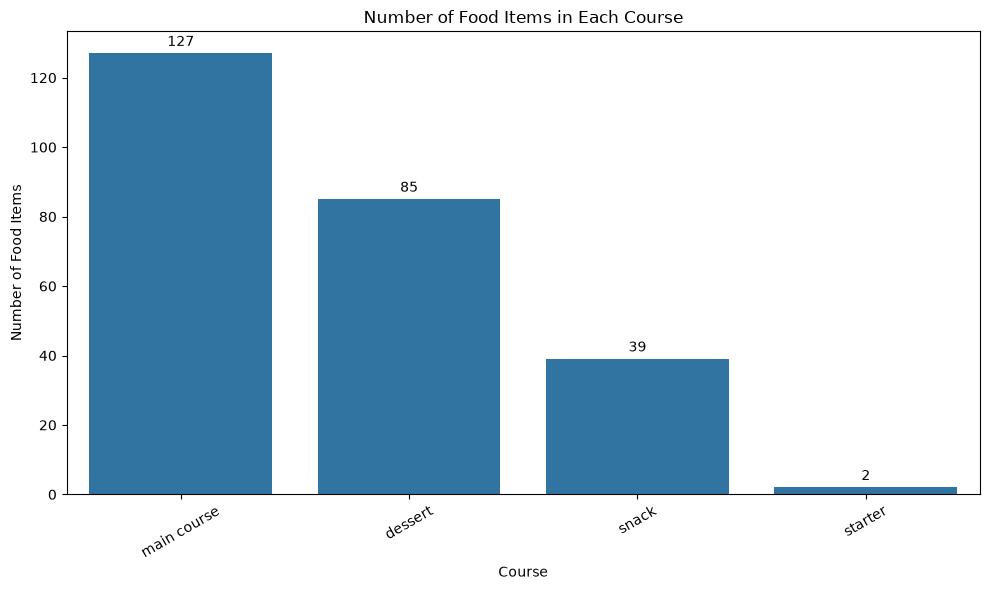

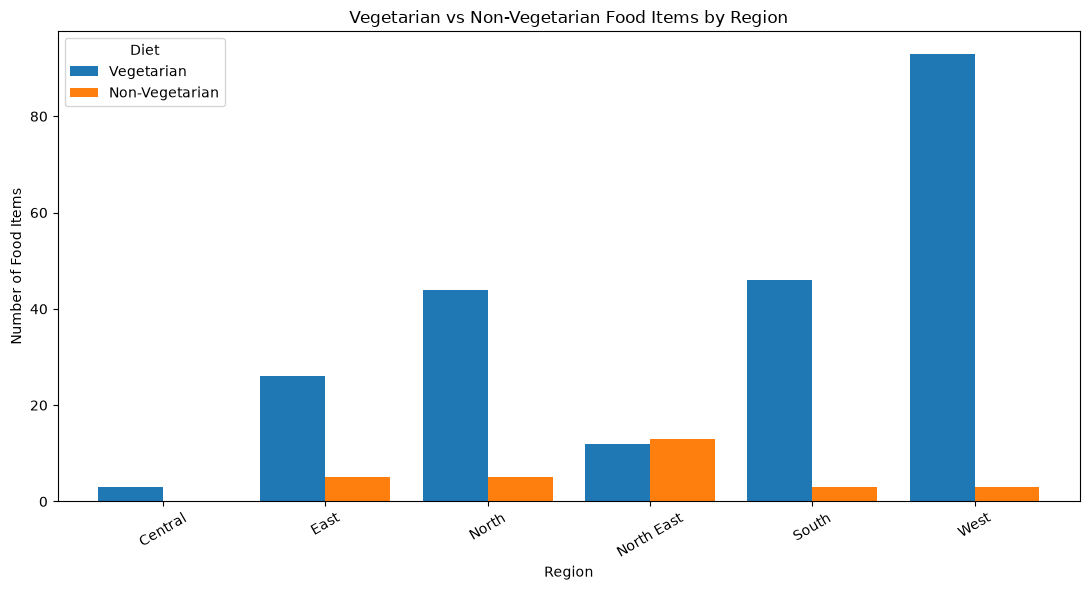

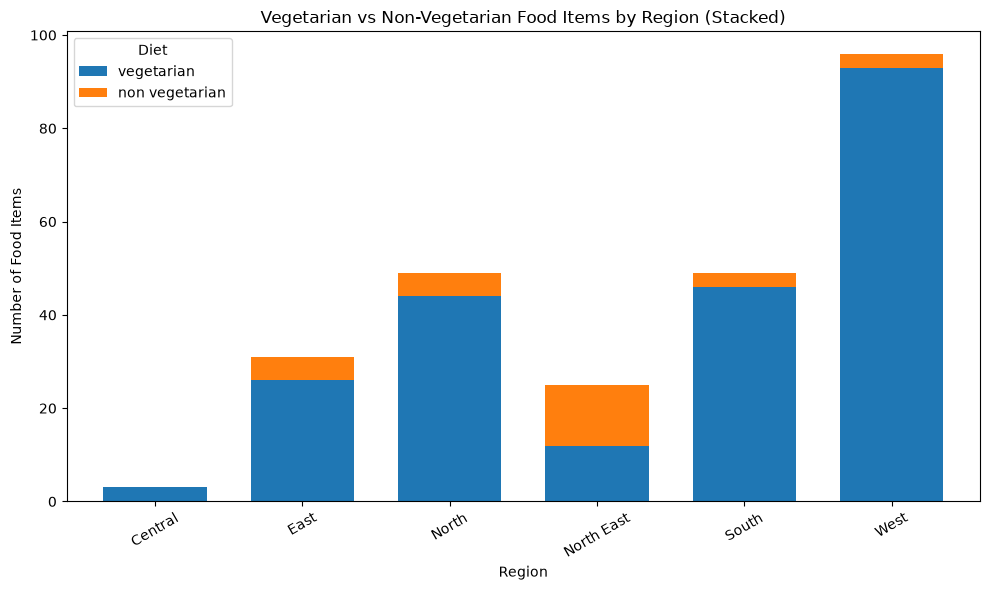

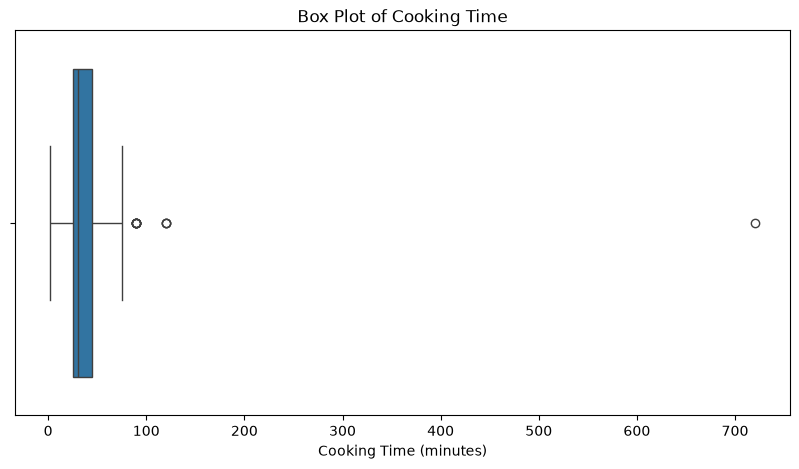

Q1: 25.0
Q3: 45.0
IQR: 20.0
Lower bound: -5.0
Upper bound: 75.0
Number of outliers: 11


,Name,cook_time
62,Shrikhand,720.0
27,Malapua,120.0
75,Biryani,120.0
114,Pindi chana,120.0
34,Rasgulla,90.0
83,Daal baati churma,90.0
115,Rajma chaval,90.0
128,Dosa,90.0
130,Idli,90.0
142,Kuzhakkattai,90.0


Cleaned dataset saved successfully!


In [13]:
#Question1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_excel('Indian_food.xlsm', engine='openpyxl')
#Step1
print(df.columns.tolist())

#Step 2: Clean the data

#A. Replace -1 in state with the mode
state_mode = df.loc[df['state'] != -1, 'state'].mode()[0]
df['state'] = df['state'].replace(-1, state_mode)

print("Mode of state:", state_mode)
print("Remaining -1 in state:", (df['state'] == -1).sum())

#B. Fill the corresponding region

region_mode = df.loc[
    (df['state'] == state_mode) &
    (df['region'] != -1),
    'region'
].mode()

if not region_mode.empty:
    df.loc[
        (df['state'] == state_mode) &
        (df['region'] == -1),
        'region'
    ] = region_mode[0]

print("Region for mode state:", region_mode.iloc[0] if not region_mode.empty else "Not found")

#C. Replace -1 in cooking time with the mean

cook_mean = df.loc[df['cook_time'] != -1, 'cook_time'].mean()

df['cook_time'] = df['cook_time'].replace(-1, cook_mean)

print("Mean cooking time:", cook_mean)
print("Remaining -1 in cook_time:", (df['cook_time'] == -1).sum())
print(df.columns.tolist())

#D. Pie chart — flavour profile distribution

flavor_counts = df['flavor_profile'].fillna('Unknown').value_counts()

plt.figure(figsize=(8, 8))
plt.pie(
    flavor_counts.values,
    labels=flavor_counts.index,
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Distribution of Food Items by Flavour Profile')
plt.axis('equal')
plt.show()

#E. Bar chart — food items by course

course_counts = df['course'].fillna('Unknown').value_counts()
course_counts = course_counts.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    x=course_counts.index,
    y=course_counts.values
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title('Number of Food Items in Each Course')
plt.xlabel('Course')
plt.ylabel('Number of Food Items')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#F. Vegetarian vs. non-vegetarian food items by region

# Standardize the Diet labels
df['Diet'] = df['Diet'].astype(str).str.strip().str.lower()

df['Diet'] = df['Diet'].replace({
    'veg': 'vegetarian',
    'non-veg': 'non vegetarian',
    'non-vegetarian': 'non vegetarian',
    'non veg': 'non vegetarian'
})

# Count food items by region and diet
diet_region = pd.crosstab(df['region'], df['Diet'])

# Keep the two categories in a consistent order where present
diet_region = diet_region.reindex(
    columns=['vegetarian', 'non vegetarian'],
    fill_value=0
)

# Plot grouped bar chart
ax = diet_region.plot(
    kind='bar',
    figsize=(11, 6),
    width=0.8
)

plt.title('Vegetarian vs Non-Vegetarian Food Items by Region')
plt.xlabel('Region')
plt.ylabel('Number of Food Items')
plt.xticks(rotation=30)
plt.legend(['Vegetarian', 'Non-Vegetarian'], title='Diet')
plt.tight_layout()
plt.show()

# plot stacked bar chart

ax = diet_region.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    width=0.7
)

ax.set_title('Vegetarian vs Non-Vegetarian Food Items by Region (Stacked)')
ax.set_xlabel('Region')
ax.set_ylabel('Number of Food Items')
ax.legend(title='Diet')

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

#G. Box plot — cooking-time distribution and outliers
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['cook_time'])

plt.title('Box Plot of Cooking Time')
plt.xlabel('Cooking Time (minutes)')
plt.show()

# Check for outliers using the IQR method
Q1 = df['cook_time'].quantile(0.25)
Q3 = df['cook_time'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['cook_time'] < lower_bound) |
    (df['cook_time'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of outliers:", len(outliers))

display(outliers[['Name', 'cook_time']].sort_values(
    by='cook_time',
    ascending=False
))

df.to_excel('Indian_food_cleaned.xlsx', index=False)
print("Cleaned dataset saved successfully!")

   finalWorth               category                personName   age  \
0      211000       Fashion & Retail  Bernard Arnault & family  74.0   
1      180000             Automotive                 Elon Musk  51.0   
2      114000             Technology                Jeff Bezos  59.0   
3      107000             Technology             Larry Ellison  78.0   
4      106000  Finance & Investments            Warren Buffett  92.0   

         country    city gender  birthYear  birthMonth  birthDay  
0         France   Paris      M     1949.0         3.0       5.0  
1  United States  Austin      M     1971.0         6.0      28.0  
2  United States  Medina      M     1964.0         1.0      12.0  
3  United States   Lanai      M     1944.0         8.0      17.0  
4  United States   Omaha      M     1930.0         8.0      30.0  
(2640, 10)
['finalWorth', 'category', 'personName', 'age', 'country', 'city', 'gender', 'birthYear', 'birthMonth', 'birthDay']


,finalWorth,category,personName,age,country,city,gender,birthYear,birthMonth,birthDay
0,211000,Fashion & Retail,Bernard Arnault & family,74.0,France,Paris,M,1949.0,3.0,5.0
1,180000,Automotive,Elon Musk,51.0,United States,Austin,M,1971.0,6.0,28.0
2,114000,Technology,Jeff Bezos,59.0,United States,Medina,M,1964.0,1.0,12.0
3,107000,Technology,Larry Ellison,78.0,United States,Lanai,M,1944.0,8.0,17.0
4,106000,Finance & Investments,Warren Buffett,92.0,United States,Omaha,M,1930.0,8.0,30.0


Total billionaires aged 30 or above: 2564


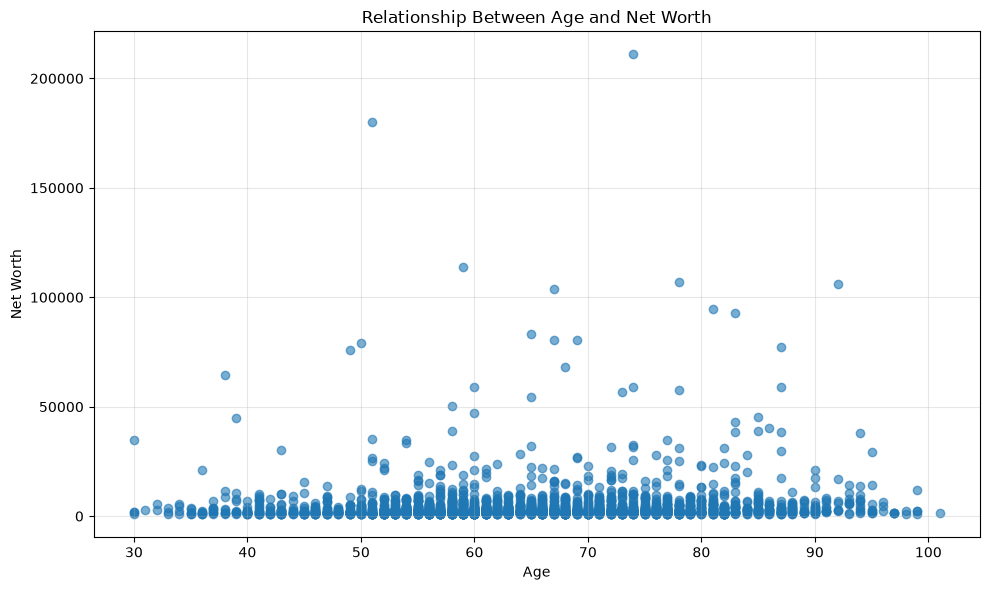

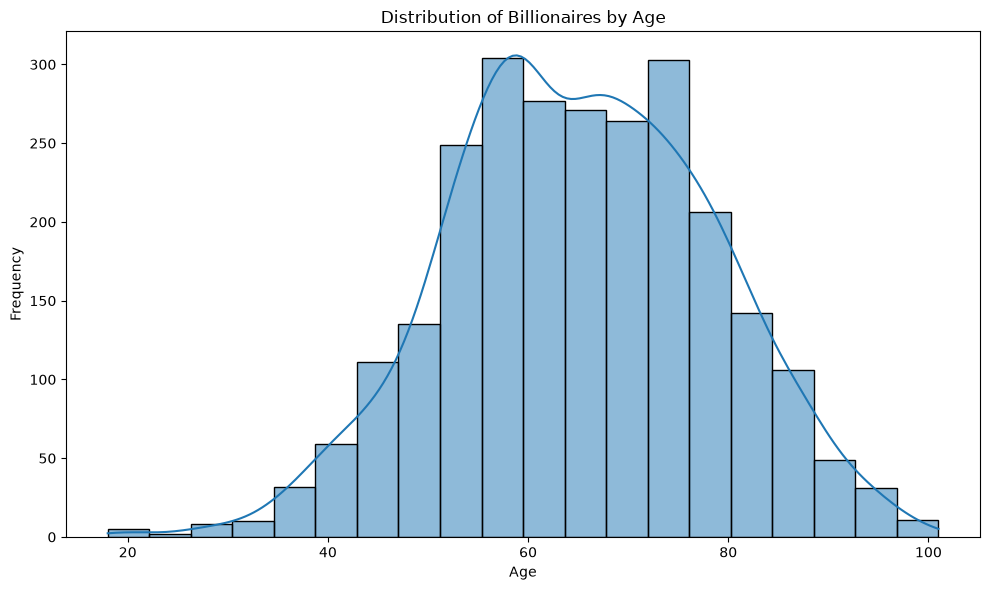

            finalWorth   age  birthYear  birthMonth  birthDay
finalWorth        1.00  0.07      -0.07        0.00      0.06
age               0.07  1.00      -1.00        0.02      0.08
birthYear        -0.07 -1.00       1.00       -0.05     -0.09
birthMonth        0.00  0.02      -0.05        1.00      0.22
birthDay          0.06  0.08      -0.09        0.22      1.00


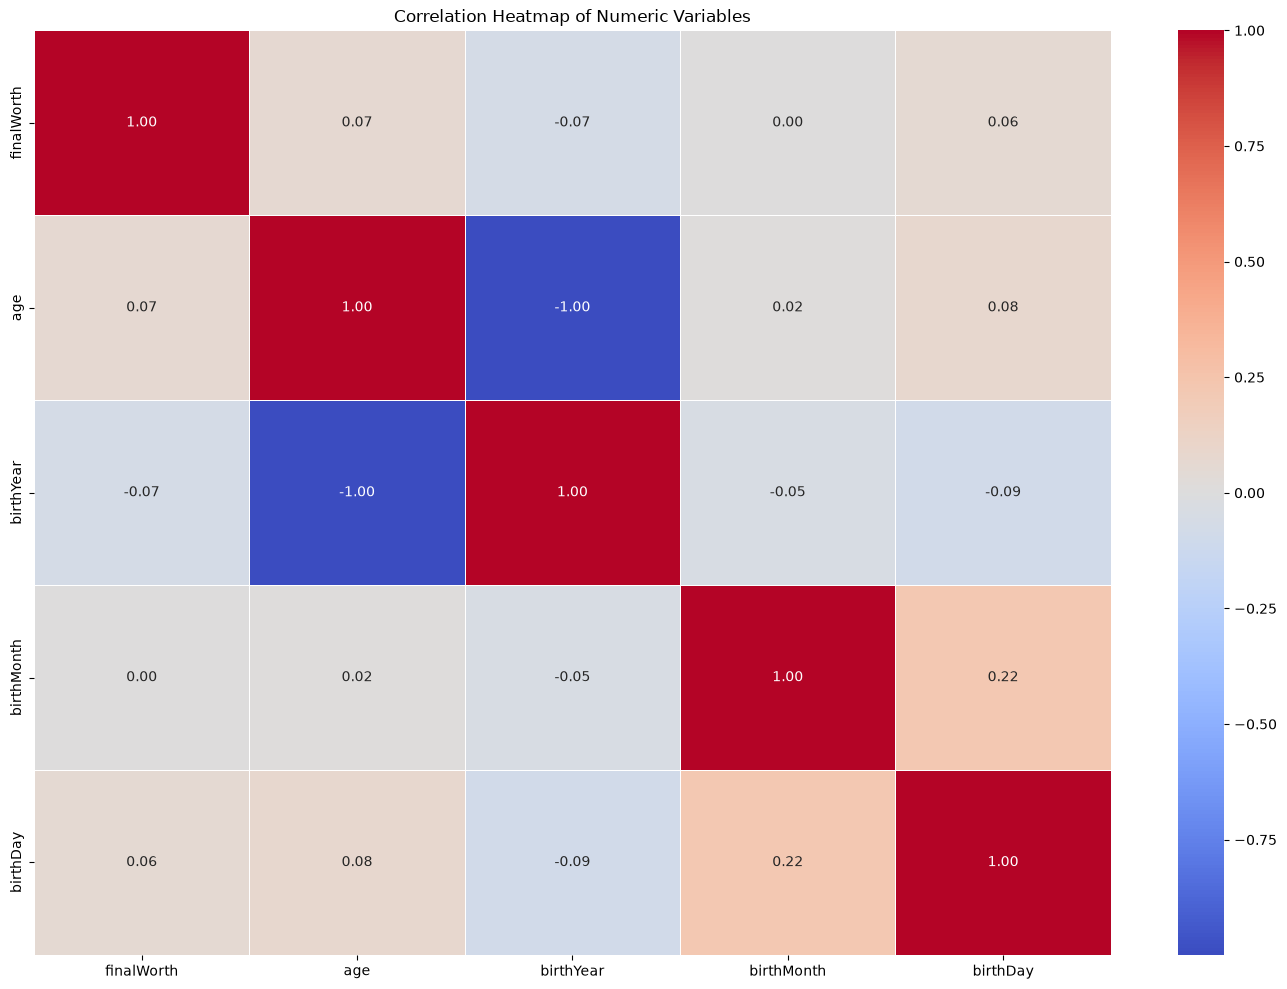

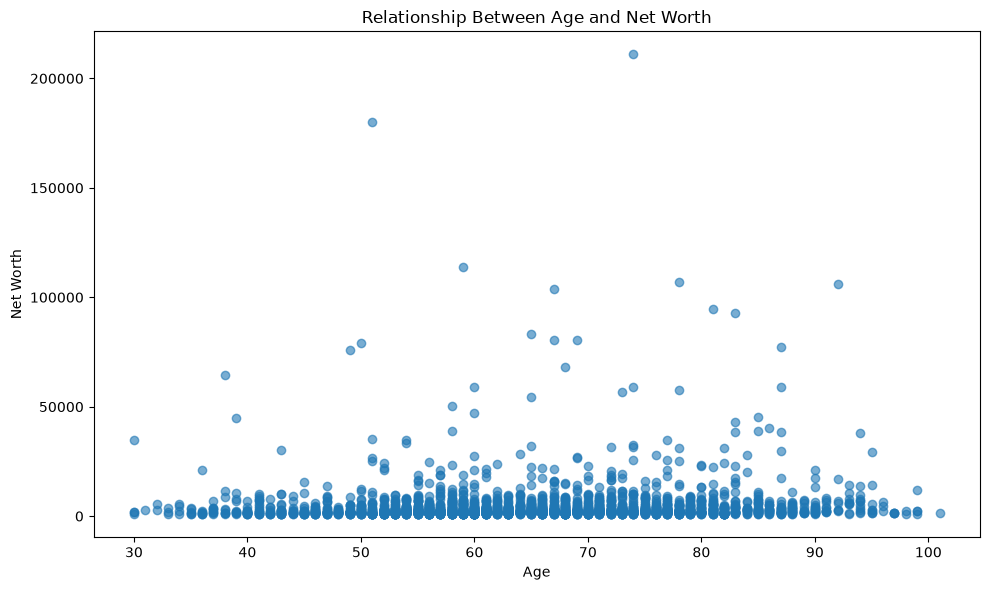

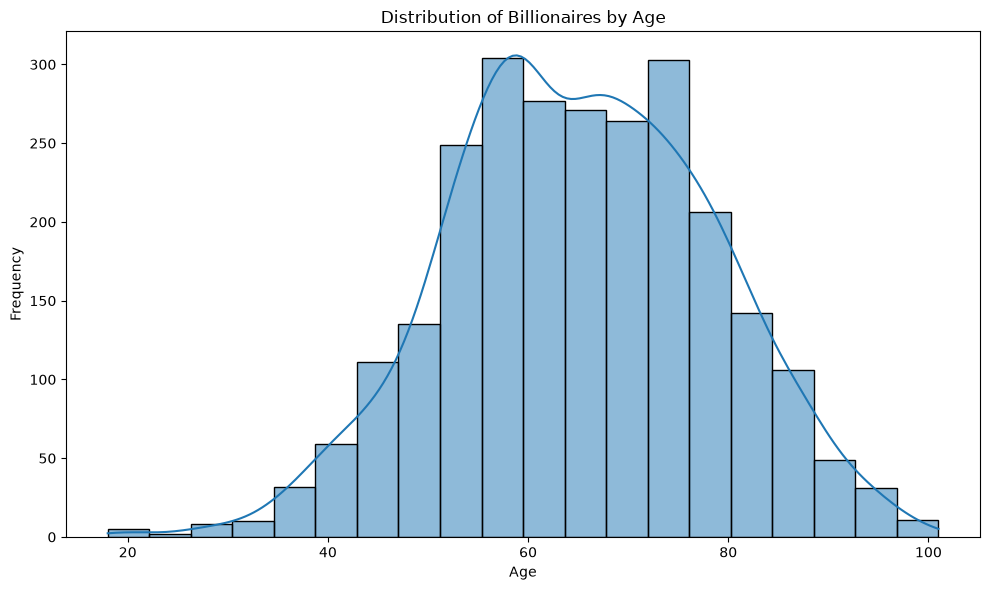

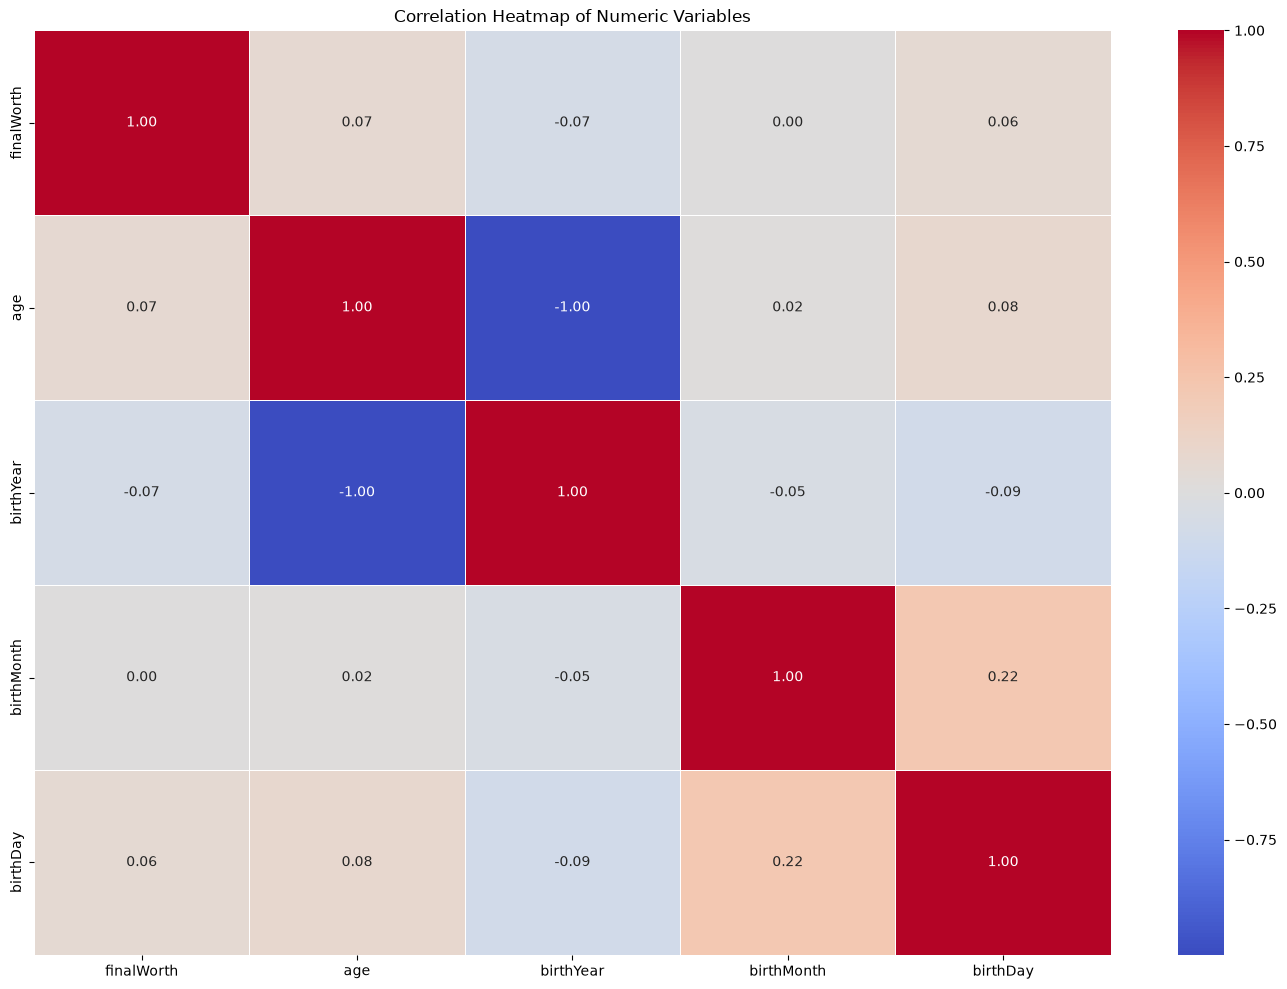

Current working directory: C:\Users\pc\Data_Science\Assignment_Python\Data_Vis

Saved visualization files:
billionaires_scatter_plot.png — Saved
billionaires_age_histogram.png — Saved
billionaires_correlation_heatmap.png — Saved


In [23]:
#Question2

# Import dataset
df = pd.read_csv('Billionaires_Stats.csv')

# Display dataset information
print(df.head())
print(df.shape)
print(df.columns.tolist())

#(a) Filter billionaires aged 30 or above and create a scatter plot
# Create a filtered DataFrame
df_age30 = df[df['age'] >= 30].copy()

# Display the filtered DataFrame
display(df_age30.head())

print("Total billionaires aged 30 or above:", len(df_age30))

#Now create a scatter plot to show the relationship between age and net worth.

plt.figure(figsize=(10, 6))

plt.scatter(
    df_age30['age'],
    df_age30['finalWorth'],
    alpha=0.6
)

plt.title('Relationship Between Age and Net Worth')
plt.xlabel('Age')
plt.ylabel('Net Worth')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#(b) Create a histogram to show the distribution of ages

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='age',
    bins=20,
    kde=True
)

plt.title('Distribution of Billionaires by Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

#(c) Create a correlation heatmap for all numeric variables
# Select numeric columns
numeric_df = df.select_dtypes(include='number')

# Calculate correlation matrix
correlation_matrix = numeric_df.corr()

# Display correlation values
print(correlation_matrix.round(2))

# Plot heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numeric Variables')
plt.tight_layout()
plt.show()

#(d) Save the figures in your current working directory

plt.figure(figsize=(10, 6))

plt.scatter(df_age30['age'], df_age30['finalWorth'], alpha=0.6)

plt.title('Relationship Between Age and Net Worth')
plt.xlabel('Age')
plt.ylabel('Net Worth')
plt.tight_layout()

plt.savefig('billionaires_scatter_plot.png', dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(10, 6))

sns.histplot(data=df, x='age', bins=20, kde=True)

plt.title('Distribution of Billionaires by Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.tight_layout()

plt.savefig('billionaires_age_histogram.png', dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numeric Variables')
plt.tight_layout()

plt.savefig('billionaires_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

#Verify the saved files
print("Current working directory:", os.getcwd())

print("\nSaved visualization files:")
for file in [
    'billionaires_scatter_plot.png',
    'billionaires_age_histogram.png',
    'billionaires_correlation_heatmap.png'
]:
    print(file, "—", "Saved" if os.path.exists(file) else "Not found")

  Student  Marks  Study_Hours  Age Category
0       A     78            8   20        A
1       B     91            5   20        B
2       C     68            7   22        A
3       D     54            3   21        B
4       E     82            7   20        C


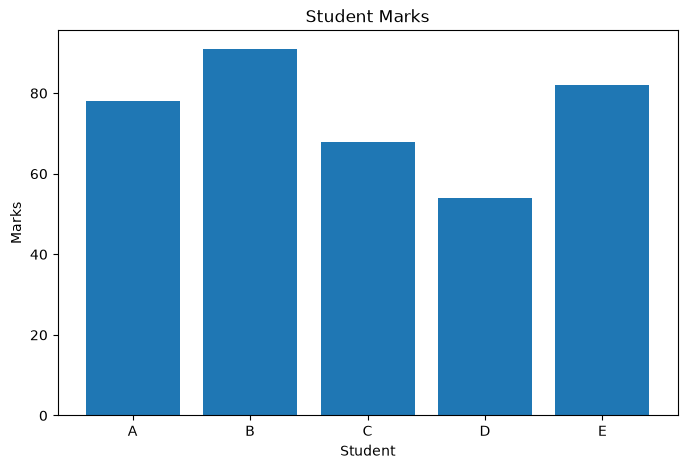

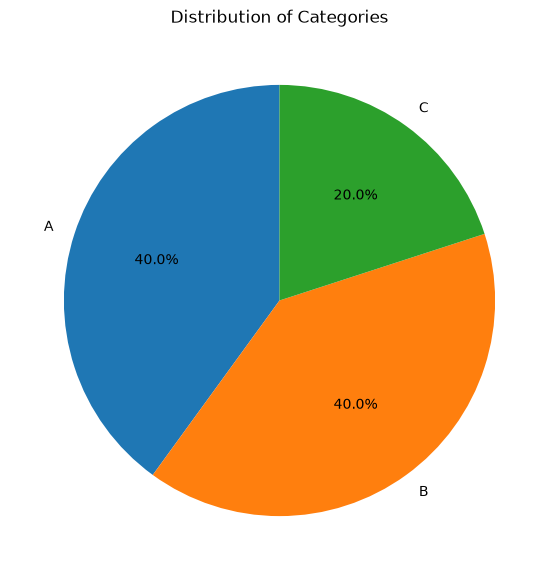

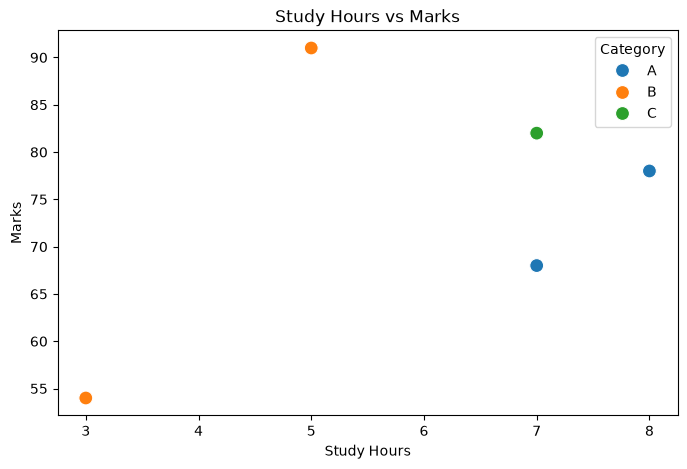

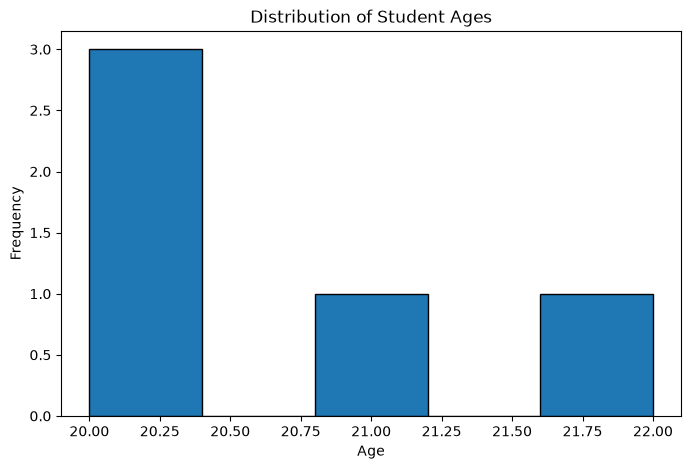

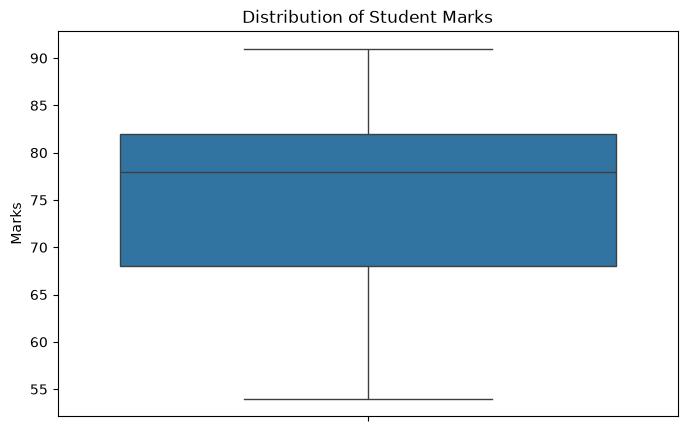

In [29]:
#Question3
# Generate random data
np.random.seed(42)

df = pd.DataFrame({
    'Student': ['A', 'B', 'C', 'D', 'E'],
    'Marks': np.random.randint(40, 100, 5),
    'Study_Hours': np.random.randint(1, 10, 5),
    'Age': np.random.randint(18, 25, 5),
    'Category': ['A', 'B', 'A', 'B', 'C']
})

print(df)

#1. Bar Chart — Matplotlib
plt.figure(figsize=(8, 5))

plt.bar(df['Student'], df['Marks'])

plt.title('Student Marks')
plt.xlabel('Student')
plt.ylabel('Marks')

plt.show()

#2. Pie Chart — Matplotlib
category_counts = df['Category'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    category_counts.values,
    labels=category_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Categories')
plt.show()

#3. Scatter Plot — Seaborn
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Study_Hours',
    y='Marks',
    hue='Category',
    s=100
)

plt.title('Study Hours vs Marks')
plt.xlabel('Study Hours')
plt.ylabel('Marks')

plt.show()

#4. Histogram — Matplotlib
plt.figure(figsize=(8, 5))

plt.hist(
    df['Age'],
    bins=5,
    edgecolor='black'
)

plt.title('Distribution of Student Ages')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

#5. Box Plot — Seaborn
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['Marks'])

plt.title('Distribution of Student Marks')
plt.ylabel('Marks')

plt.show()